# BPIC-17 — Section 2.3: decision mining on the final model

This notebook adds a **decision block to every XOR-split** of the final model (`models/final/v04`, W_ + O_ + A_ log with 16 activities),
following de Leoni & van der Aalst (SAC 2013), *Data-aware process mining: discovering decisions in
processes using alignments*:

1. every case is **aligned** with the Petri net of the final model; the alignment tells which branch
   of every XOR-split the case took, also for silent (invisible) branches;
2. every visit of an XOR-split becomes one **observation**: the attribute values known at that moment
   (latest value written by the events aligned so far) → the branch taken;
3. one **decision tree** per XOR-split (CART from scikit-learn, the paper uses C4.5), trained on the
   training cases and evaluated on the test cases against the **majority-branch baseline**.

The code of steps 1–3 is in `src/decision_mining.py`; the final model is built by `src/final_model.py`.

## 0. Setup

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"  # no progress bars (must be set before tqdm is imported)
from pathlib import Path
import hashlib
import shutil
import warnings

import numpy as np
import pandas as pd
import pm4py
from IPython.display import SVG, display

from src.prep import CASE, ACT, SEED, OUTCOME_ACTIVITIES, load_event_log, drop_open_cases
from src.abstraction_w import build_log
from src.decision_mining import (LEAKING, branch_names, decision_instances, mine, offer_fate_table,
                                 parse_flows, rules_text, short_rule)
from src.draw_bpmn import draw, preview

warnings.filterwarnings("ignore")
if os.environ.get("PYTHONHASHSEED") != "0":
    # alignments with equally good options and the order of the one-hot columns depend on
    # Python's string hashing; start Jupyter with PYTHONHASHSEED=0 for identical results
    print("WARNING: PYTHONHASHSEED is not 0 - small differences between runs are possible (see README)")
np.random.seed(SEED)

GRAPHVIZ_FALLBACK = Path("/opt/anaconda3/envs/graphviz/bin")
if shutil.which("dot") is None and (GRAPHVIZ_FALLBACK / "dot").exists():
    os.environ["PATH"] = f"{GRAPHVIZ_FALLBACK}{os.pathsep}{os.environ['PATH']}"
assert shutil.which("dot"), "Graphviz not found"

DATA_DIR = Path("BPIC-17 Data")
MODEL_DIR = Path("models/final/v04")
TABLE_DIR, FIG_DIR = Path("tables"), Path("figures")
TABLE_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)
print("pm4py", pm4py.__version__, "| pandas", pd.__version__)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.12 | pandas 3.1.1


## 1. Final model and its decision points

A decision point is a place of the Petri net with more than one outgoing transition, i.e. an
XOR-split of the BPMN. Merging gateways do not need a decision. The final model has **17 XOR-splits**,
numbered D1–D17 in process order. Gateways are identified by their position (gateway id), not by
activity labels, because O_Create Offer and O_Sent occur twice (first offer and later offers).

In [2]:
df, _ = drop_open_cases(load_event_log(DATA_DIR / "BPI Challenge 2017.xes", DATA_DIR / "bpic17_eventlog.pkl"))
log, _ = build_log(df)  # W_ + O_ + A_ log (16 activities)
train_ids = set(Path("splits/train_cases.txt").read_text().split("\n"))
test_ids = set(Path("splits/test_cases.txt").read_text().split("\n"))

net, im, fm = pm4py.read_pnml(str(MODEL_DIR / "model.pnml"))
flows = parse_flows((MODEL_DIR / "model.edges").read_text())
names = branch_names(net, flows)

ORDER = ["xor_sub", "xor_hl", "xor_wca", "xor_co_again", "xor_se_again", "xor_cao_out",
         "xor_lco_again", "xor_lse_again", "xor_bypass", "xor_ret", "xor_after_va", "xor_after_cif",
         "xor_out", "xor_oc", "xor_oc_again", "xor_ref", "xor_ref_again"]
QUESTION = {
    "xor_sub": "online application (A_Submitted) or not",
    "xor_hl": "online: W_Handle leads or not",
    "xor_wca": "online: W_Complete application or skip",
    "xor_co_again": "first offers: create one more offer?",
    "xor_se_again": "first offers: send one more, or W_Call after offers",
    "xor_cao_out": "after W_Call after offers: later offer or continue",
    "xor_lco_again": "later offers: create one more?",
    "xor_lse_again": "later offers: send one more, or continue",
    "xor_bypass": "validation or directly to the outcome",
    "xor_ret": "O_Returned during validation?",
    "xor_after_va": "after validation: W_Call incomplete files or outcome",
    "xor_after_cif": "after W_Call incomplete files: validate / later offer / outcome",
    "xor_out": "outcome: cancelled / accepted / denied",
    "xor_oc": "after cancelled/pending: cancel open offers?",
    "xor_oc_again": "cancel one more offer?",
    "xor_ref": "after denied: refuse offers?",
    "xor_ref_again": "refuse one more offer?",
}
DID = {gw: f"D{i + 1}" for i, gw in enumerate(ORDER)}
found = {gw for gw, _ in names}
assert found == set(ORDER), found ^ set(ORDER)

points = pd.DataFrame([{"id": DID[gw], "gateway": gw, "decision": QUESTION[gw],
                        "branches": " | ".join(sorted({b for (g, _), b in names.items() if g == gw}))}
                       for gw in ORDER])
points

,id,gateway,decision,branches
0,D1,xor_sub,online application (A_Submitted) or not,A_Submitted | not online
1,D2,xor_hl,online: W_Handle leads or not,W_Handle leads | no W_Handle leads
2,D3,xor_wca,online: W_Complete application or skip,W_Complete application | skip W_Complete application
3,D4,xor_co_again,first offers: create one more offer?,O_Create Offer | O_Sent
4,D5,xor_se_again,"first offers: send one more, or W_Call after offers",O_Sent | W_Call after offers
5,D6,xor_cao_out,after W_Call after offers: later offer or continue,O_Create Offer (later offer) | continue (validation / outcome)
6,D7,xor_lco_again,later offers: create one more?,O_Create Offer (later offer) | O_Sent (later offer)
7,D8,xor_lse_again,"later offers: send one more, or continue",O_Sent (later offer) | continue (validation / outcome)
8,D9,xor_bypass,validation or directly to the outcome,W_Validate application | to outcome
9,D10,xor_ret,O_Returned during validation?,O_Returned | no O_Returned


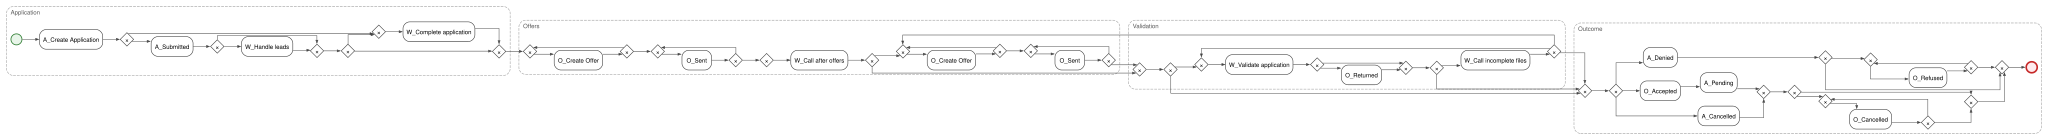

In [3]:
display(SVG(preview(MODEL_DIR)))

## 2. Attributes and information leakage

Available attributes: case level `LoanGoal`, `ApplicationType`, `RequestedAmount`; offer level (written
only on `O_Create Offer`) `OfferedAmount`, `MonthlyCost`, `NumberOfTerms`, `FirstWithdrawalAmount`,
`Accepted`, `Selected`, `CreditScore`. The case history at the moment of the decision:
`n_offers` (offers so far), `n_later_offers` (offers after the first O_Sent), `n_validate`
(W_Validate application so far), `n_incomplete` (W_Call incomplete files so far), `returned` (O_Returned has
occurred, 0/1), `open_offers` (offers not yet cancelled / refused / accepted) and `days_since_start`.

The duration and the end type (complete / ate_abort / withdraw) of the W_ work items are **not** used:
they are only known when the work item ends and reveal the later outcome.

An attribute can only explain a decision if its value is known **before** the decision. The offer
attributes are written when the offer is created, so below we compare them with what happens to the
**same offer** later.

In [4]:
off = offer_fate_table(df)  # original log: O_Create Offer is followed by O_Created (OfferID)
rows = []
for attr in ["Selected", "CreditScore > 0", "Accepted"]:
    for val, g in off.groupby(attr):
        rows.append({"attribute": attr, "value": val, "offers": len(g),
                     "later O_Accepted %": round(100 * (g.fate == "O_Accepted").mean(), 1),
                     "later O_Cancelled %": round(100 * (g.fate == "O_Cancelled").mean(), 1),
                     "later O_Refused %": round(100 * (g.fate == "O_Refused").mean(), 1),
                     "later O_Returned %": round(100 * g.returned.mean(), 1)})
leak = pd.DataFrame(rows)
leak.to_csv(TABLE_DIR / "dm_leakage.csv", index=False)
leak

,attribute,value,offers,later O_Accepted %,later O_Cancelled %,later O_Refused %,later O_Returned %
0,Selected,False,21092,0.0,94.4,5.6,7.3
1,Selected,True,21723,79.3,4.5,16.2,100.0
2,CreditScore > 0,False,27555,7.2,75.8,17.0,29.0
3,CreditScore > 0,True,15260,100.0,0.0,0.0,100.0
4,Accepted,False,12782,25.1,51.1,23.8,53.7
5,Accepted,True,30033,46.7,47.8,5.5,54.6


The table shows for `Selected`, `CreditScore > 0` and `Accepted` what happens later to the same offer;
a value that (almost) determines the later fate leaks the outcome.

`Selected` and `CreditScore` therefore encode information from the future of the case and are
**excluded** from the main analysis. For comparison, section 4 also reports the results with them.

## 3. Decision observations from the alignments

In [5]:
def cached_instances(part, ids):
    """Observations for the train or test cases; cached per model version (pnml hash)."""
    h = hashlib.md5((MODEL_DIR / "model.pnml").read_bytes()).hexdigest()[:10]
    path = MODEL_DIR / f"dm_instances_{part}_{h}.pkl"
    if path.exists():
        return pd.read_pickle(path)
    inst = decision_instances(log[log[CASE].isin(ids)], net, im, fm, flows)
    inst.to_pickle(path)
    return inst

train_inst = cached_instances("train", train_ids)
test_inst = cached_instances("test", test_ids)
obs = (train_inst.groupby("gateway").size().rename("train obs").to_frame()
       .join(test_inst.groupby("gateway").size().rename("test obs")).reindex(ORDER))
obs.index = [f"{DID[g]} {g}" for g in obs.index]
print(f"{len(train_inst)} train and {len(test_inst)} test observations")
obs

284675 train and 122044 test observations


,train obs,test obs
D1 xor_sub,21988,9423
D2 xor_hl,14234,6105
D3 xor_wca,14234,6105
D4 xor_co_again,24768,10543
D5 xor_se_again,24061,10253
D6 xor_cao_out,21988,9423
D7 xor_lco_again,4557,1928
D8 xor_lse_again,5084,2129
D9 xor_bypass,23231,9971
D10 xor_ret,27007,11716


## 4. Decision trees

Trees of depth ≤ 3 with at least 1 % of the observations (and ≥ 20) per leaf, so that the rules
stay readable. Branches are often very unbalanced, therefore besides **accuracy** we report
**macro-F1** (mean F1 over all branches): the majority baseline can have a high accuracy, but its
macro-F1 is low because it never predicts the rare branches.

In [6]:
res, trees = mine(train_inst, test_inst, drop_leaking=True)
res["id"] = res.gateway.map(DID)
res["decision"] = res.gateway.map(QUESTION)
res["Δ macro-F1"] = (res["tree macro-F1"] - res["baseline macro-F1"]).round(3)
res["explained"] = np.where(res["Δ macro-F1"] >= 0.1, "yes", np.where(res["Δ macro-F1"] >= 0.03, "partly", "no"))
def main_rule(g, explained):
    if explained == "no":
        major = train_inst[train_inst.gateway == g]["branch"].value_counts(normalize=True)
        return f"no rule (mostly {major.index[0]}, {100 * major.iloc[0]:.0f}%)"
    return short_rule(*trees[g]).replace("\n", "; ")
res["main rule"] = [main_rule(g, e) for g, e in zip(res.gateway, res.explained)]
res = res.set_index("gateway").loc[ORDER].reset_index()
main_cols = ["id", "gateway", "decision", "main rule", "n train", "n test", "baseline acc", "tree acc",
             "baseline macro-F1", "tree macro-F1", "Δ macro-F1", "explained", "top features"]
res[main_cols].to_csv(TABLE_DIR / "decision_mining.csv", index=False)
res[main_cols]

,id,gateway,decision,main rule,n train,n test,baseline acc,tree acc,baseline macro-F1,tree macro-F1,Δ macro-F1,explained,top features
0,D1,xor_sub,online application (A_Submitted) or not,"if ApplicationType != Limit raise: A_Submitted (72%), not online (28%); else: not online (100%)",21988,9423,0.648,0.829,0.393,0.781,0.388,yes,"case:ApplicationType_Limit raise 0.53, case:RequestedAmount 0.47, case:LoanGoal_Unknown 0.00"
1,D2,xor_hl,online: W_Handle leads or not,"no rule (mostly no W_Handle leads, 82%)",14234,6105,0.820,0.820,0.450,0.450,0.000,no,"case:RequestedAmount 0.50, case:LoanGoal_Existing loan takeover 0.39, case:LoanGoal_Not speficied 0.11"
2,D3,xor_wca,online: W_Complete application or skip,"no rule (mostly W_Complete application, 91%)",14234,6105,0.903,0.903,0.475,0.475,0.000,no,"days_since_start 0.91, case:RequestedAmount 0.06, case:LoanGoal_Car 0.04"
3,D4,xor_co_again,first offers: create one more offer?,"no rule (mostly O_Sent, 89%)",24768,10543,0.894,0.894,0.472,0.472,0.000,no,"case:ApplicationType_New credit 0.41, FirstWithdrawalAmount 0.30, case:LoanGoal_Not speficied 0.20"
4,D5,xor_se_again,"first offers: send one more, or W_Call after offers","if open_offers <= 1: W_Call after offers (100%); else: W_Call after offers (51%), O_Sent (49%)",24061,10253,0.919,0.924,0.479,0.578,0.099,partly,"open_offers 1.00, FirstWithdrawalAmount 0.00"
5,D6,xor_cao_out,after W_Call after offers: later offer or continue,"no rule (mostly continue (validation / outcome), 86%)",21988,9423,0.865,0.865,0.464,0.464,0.000,no,"case:ApplicationType_New credit 0.40, OfferedAmount 0.29, open_offers 0.24"
6,D7,xor_lco_again,later offers: create one more?,"no rule (mostly O_Sent (later offer), 94%)",4557,1928,0.942,0.942,0.485,0.485,0.000,no,"n_offers 0.54, returned 0.33, days_since_start 0.12"
7,D8,xor_lse_again,"later offers: send one more, or continue","if n_offers <= 3: continue (validation / outcome) (88%); else: continue (validation / outcome) (62%), O_Sent (later ...",5084,2129,0.853,0.854,0.460,0.507,0.047,partly,"n_offers 0.61, returned 0.16, days_since_start 0.12"
8,D9,xor_bypass,validation or directly to the outcome,"no rule (mostly W_Validate application, 70%)",23231,9971,0.709,0.709,0.415,0.415,0.000,no,"FirstWithdrawalAmount 0.42, NumberOfTerms 0.23, case:ApplicationType_New credit 0.19"
9,D10,xor_ret,O_Returned during validation?,if no O_Returned yet: O_Returned (93%); else: no O_Returned (95%),27007,11716,0.557,0.938,0.358,0.937,0.579,yes,"returned 0.97, n_later_offers 0.01, days_since_start 0.01"


In [7]:
res_leak, _ = mine(train_inst, test_inst, drop_leaking=False)
cmp = (res.set_index("gateway")[["id", "tree acc", "tree macro-F1"]]
       .join(res_leak.set_index("gateway")[["tree acc", "tree macro-F1", "top features"]], rsuffix=" (with leaking)"))
cmp = cmp.loc[ORDER]
cmp.to_csv(TABLE_DIR / "decision_mining_with_leaking.csv")
cmp[cmp["tree macro-F1 (with leaking)"] - cmp["tree macro-F1"] > 0.02]

,id,tree acc,tree macro-F1,tree acc (with leaking),tree macro-F1 (with leaking),top features
gateway,,,,,,
xor_lse_again,D8,0.854,0.507,0.861,0.576,"Selected_False 0.64, n_offers 0.24, days_since_start 0.11"
xor_bypass,D9,0.709,0.415,0.915,0.904,"Selected_True 0.92, open_offers 0.06, Accepted_False 0.01"
xor_after_cif,D12,0.670,0.268,0.691,0.467,"Selected_False 0.45, open_offers 0.23, FirstWithdrawalAmount 0.14"
xor_out,D13,0.874,0.774,0.923,0.879,"returned 0.71, CreditScore 0.20, case:ApplicationType_New credit 0.08"


Decisions where `Selected`/`CreditScore` improve the tree are listed above; they only look better because
these attributes already contain the later result. The main results do not use them.

## 5. Rules

In [8]:
rule_file = []
for gw in ORDER:
    tree, cols = trees[gw]
    r = res.set_index("gateway").loc[gw]
    head = (f"{DID[gw]} {gw}: {QUESTION[gw]}\n  acc {r['tree acc']:.3f} (baseline {r['baseline acc']:.3f}), "
            f"macro-F1 {r['tree macro-F1']:.3f} (baseline {r['baseline macro-F1']:.3f})")
    rule_file.append(head + "\n" + rules_text(tree, cols))
(TABLE_DIR / "decision_rules.txt").write_text("\n\n".join(rule_file))
print("\n\n".join(rule_file))   # all rules also in tables/decision_rules.txt

D1 xor_sub: online application (A_Submitted) or not
  acc 0.829 (baseline 0.648), macro-F1 0.781 (baseline 0.393)
|--- case:ApplicationType_Limit raise <= 0.5
|   |--- case:RequestedAmount <= 4250.0
|   |   |--- case:LoanGoal_Unknown <= 0.5
|   |   |   |--- class: not online
|   |   |--- case:LoanGoal_Unknown >  0.5
|   |   |   |--- class: not online
|   |--- case:RequestedAmount >  4250.0
|   |   |--- case:RequestedAmount <= 20295.0
|   |   |   |--- class: A_Submitted
|   |   |--- case:RequestedAmount >  20295.0
|   |   |   |--- class: A_Submitted
|--- case:ApplicationType_Limit raise >  0.5
|   |--- class: not online


D2 xor_hl: online: W_Handle leads or not
  acc 0.820 (baseline 0.820), macro-F1 0.450 (baseline 0.450)
|--- case:LoanGoal_Existing loan takeover <= 0.5
|   |--- case:RequestedAmount <= 9625.0
|   |   |--- case:RequestedAmount <= 5775.0
|   |   |   |--- class: no W_Handle leads
|   |   |--- case:RequestedAmount >  5775.0
|   |   |   |--- class: no W_Handle leads
|   |--

## 6. BPMN with decision blocks

Every XOR-split gets an id (D1–D17) and a decision block with the root rule of its tree (majority
branch and its share on each side, the second branch when it has ≥ 25 %) and the test scores
(tree vs. majority baseline). For decisions the attributes do not explain (Δ macro-F1 < 0.03), the
block says so and gives the majority branch. Full trees: `tables/decision_rules.txt`.

For the report the model is wrapped into four rows, one per block of the process. Flows between rows
are drawn as BPMN **link events**: a filled circle (throw) at the end of a row continues at the white
circle (catch) with the same letter.

D1: if ApplicationType != Limit raise: A_Submitted (72%), not online (28%) | else: not online (100%) | acc 0.83 (base 0.65) | F1 0.78 (base 0.39)
D2: no rule found | mostly no W_Handle leads (82%) | acc 0.82 (base 0.82) | F1 0.45 (base 0.45)
D3: no rule found | mostly W_Complete application (91%) | acc 0.90 (base 0.90) | F1 0.47 (base 0.47)
D4: no rule found | mostly O_Sent (89%) | acc 0.89 (base 0.89) | F1 0.47 (base 0.47)
D5: if open_offers <= 1: W_Call after offers (100%) | else: W_Call after offers (51%), O_Sent (49%) | acc 0.92 (base 0.92) | F1 0.58 (base 0.48)
D6: no rule found | mostly continue (validation / outcome) (86%) | acc 0.86 (base 0.86) | F1 0.46 (base 0.46)
D7: no rule found | mostly O_Sent (later offer) (94%) | acc 0.94 (base 0.94) | F1 0.48 (base 0.48)
D8: if n_offers <= 3: continue (validation / outcome) (88%) | else: continue (validation / outcome) (62%), O_Sent (later offer) (38%) | acc 0.85 (base 0.85) | F1 0.51 (base 0.46)
D9: no rule found | mostly W_Validate a

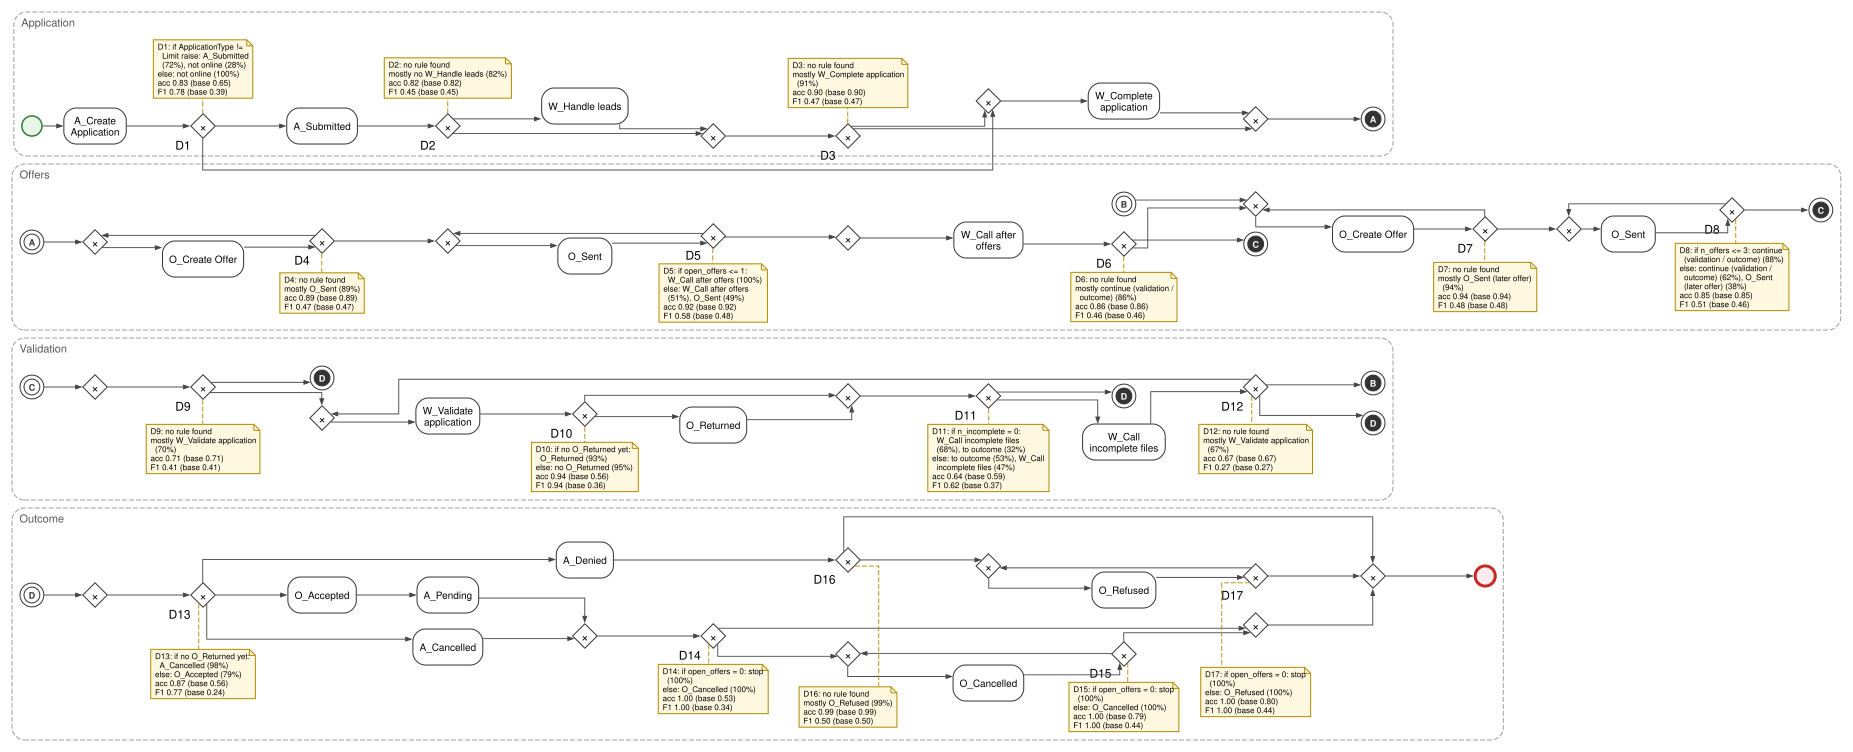

In [9]:
def note(gw):
    r = res.set_index("gateway").loc[gw]
    tree, cols = trees[gw]
    scores = (f"acc {r['tree acc']:.2f} (base {r['baseline acc']:.2f})\n"
              f"F1 {r['tree macro-F1']:.2f} (base {r['baseline macro-F1']:.2f})")
    if r["explained"] == "no":
        major = train_inst[train_inst.gateway == gw]["branch"].value_counts(normalize=True)
        rule = f"no rule found\nmostly {major.index[0]} ({100 * major.iloc[0]:.0f}%)"
    else:
        rule = short_rule(tree, cols)
    return f"{DID[gw]}: {rule}\n{scores}"

ROWS = [["Application"], ["Offers"], ["Validation"], ["Outcome"]]
notes = {gw: note(gw) for gw in ORDER}
decisions_svg = draw(MODEL_DIR, notes=notes, gateway_ids=DID, out_base=FIG_DIR / "final_model_decisions",
                     rows=ROWS, compact=True)
draw(MODEL_DIR, gateway_ids=DID, out_base=FIG_DIR / "final_model", rows=ROWS, compact=True, tight=True)
for gw in ORDER:
    print(notes[gw].replace("\n", " | "))
display(SVG(decisions_svg))

## 7. Output

* `tables/decision_mining.csv/.tex`: main rule, accuracy and macro-F1 of tree vs. baseline for D1–D17
* `tables/decision_mining_with_leaking.csv`: same with `Selected`/`CreditScore` (not used, for comparison)
* `tables/dm_leakage.csv`: offer attributes vs. later fate of the offer
* `tables/decision_rules.txt`: full rules of all 17 trees
* `figures/final_model.pdf/.png`: final BPMN v04 (four rows, D1–D17 at the XOR-splits)
* `figures/final_model_decisions.pdf/.png`: the same with a decision block at every XOR-split (appendix)